In [1]:
import numpy as np
import pandas as pd
from itertools import combinations_with_replacement
import matplotlib.pyplot as plt

In [2]:
# Считываем данные и выделяем признаки и целевую переменную
data = pd.read_csv('housing.csv')
X = data.drop(columns=["MEDV"])
y = data["MEDV"]

In [3]:
def fit(X, y):
    """Решение задачи линейной регрессии с помощью формулы нормального уравнения."""
    X = np.c_[np.ones(len(X)), X]
    return np.linalg.solve(X.T @ X, X.T @ y)

def predict(X, w):
    """Предсказание значений на основе обученной модели."""
    X = np.c_[np.ones(len(X)), X]
    return X @ w

def MAE(y_true, y_pred):
    """Вычисление средней абсолютной ошибки."""
    return np.mean(np.abs(y_true - y_pred))

In [4]:
np.random.seed(46)
indices = np.random.permutation(len(X))
test_size = int(0.22 * len(X))
train_indices = indices[test_size:]
test_indices = indices[:test_size]

# Разделяем данные на обучающую и тестовую выборки
X_train = X.iloc[train_indices]
X_test = X.iloc[test_indices]
y_train = y.iloc[train_indices]
y_test = y.iloc[test_indices]

In [5]:
def scale(X_train, X_test, with_mean=False, with_std=False):
    """Масштабирование данных с центрированием и нормализацией."""
    if with_mean:
        mean = X_train.mean()
        X_train = X_train - mean
        X_test = X_test - mean
    if with_std:
        std = X_train.std()
        X_train = X_train / std
        X_test = X_test / std
    return X_train, X_test

def poly_features(X, degree=2):
    """Генерация полиномиальных признаков до заданной степени."""
    X_poly = X.copy()
    cols = X.columns.tolist()
    new_cols = {}
    for d in range(2, degree + 1):
        for combo in combinations_with_replacement(cols, d):
            name = "*".join(combo)
            new_cols[name] = X[list(combo)].prod(axis=1)
    return pd.concat([X_poly, pd.DataFrame(new_cols, index=X.index)], axis=1)

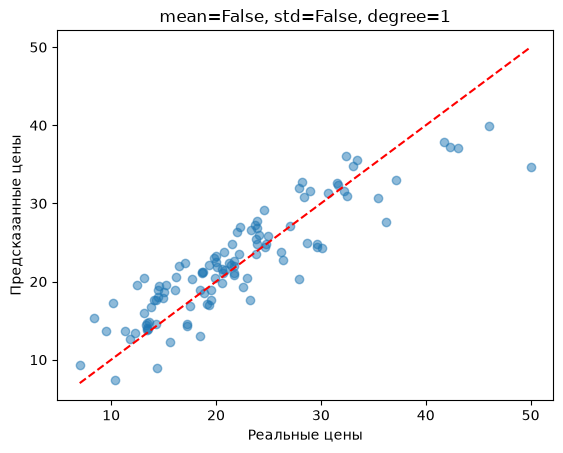

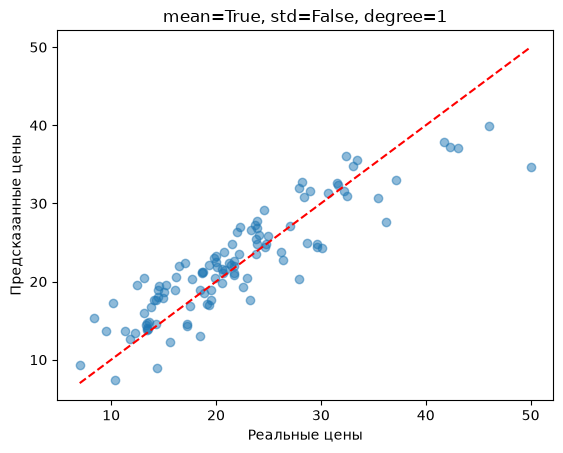

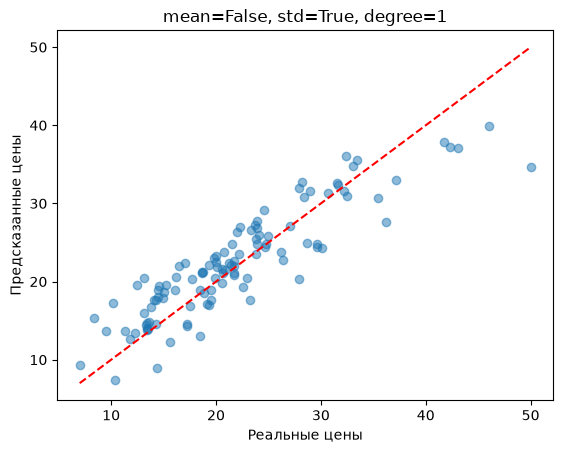

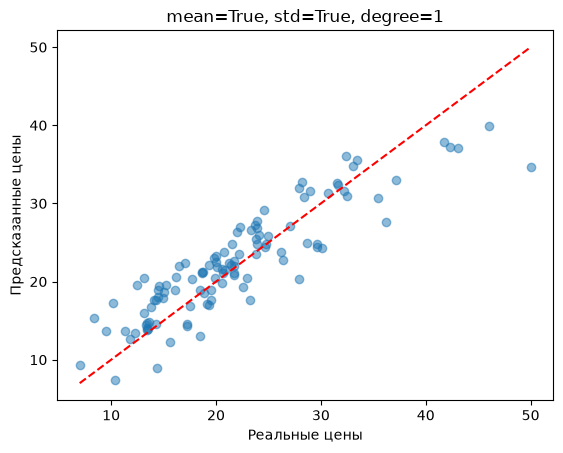

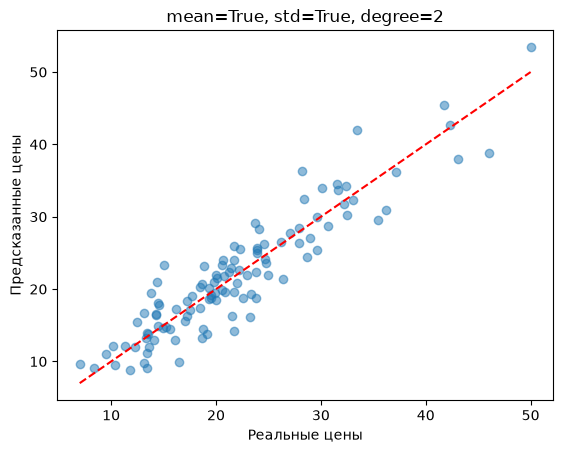

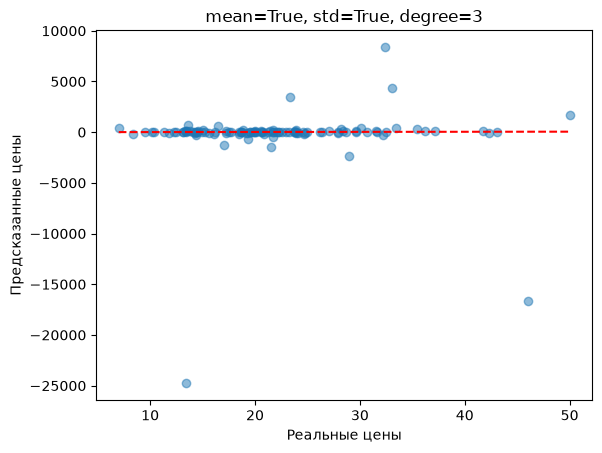

,with_mean,with_std,degree,MAE_train,MAE_test,Cond
0,False,False,1,3.424451e+00,2.934443,2.237646e+08
1,True,False,1,3.424451e+00,2.934443,9.950514e+06
2,False,True,1,3.424451e+00,2.934443,1.162587e+05
3,True,True,1,3.424451e+00,2.934443,9.731328e+01
4,True,True,2,1.738915e+00,2.560596,1.098921e+17
5,True,True,3,1.642302e-08,663.939117,8.634758e+19


In [6]:
np.seterr(all="ignore")

params = [(False, False, 1), (True, False, 1), (False, True, 1),
          (True, True, 1), (True, True, 2), (True, True, 3)]

result = pd.DataFrame({
    'with_mean': [False, True, False, True, True, True],
    'with_std': [False, False, True, True, True, True],
    'degree': [1, 1, 1, 1, 2, 3],
    'MAE_train': [0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    'MAE_test': [0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    'Cond': [0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
})

for param in params:
    with_mean, with_std, degree = param
    X_train_scaled, X_test_scaled = scale(X_train, X_test,
                                          with_mean=with_mean,
                                          with_std=with_std)

    X_train_poly = poly_features(X_train_scaled, degree=degree)
    X_test_poly = poly_features(X_test_scaled, degree=degree)

    w = fit(X_train_poly, y_train) # Вычисляем веса модели на обучающей выборке
    y_pred_train = predict(X_train_poly, w) # Предсказываем значения на обучающей выборке
    mae_train = MAE(y_train, y_pred_train) # Вычисляем MAE на обучающей выборке

    y_pred_test = predict(X_test_poly, w) # Предсказываем значения на тестовой выборке
    mae_test = MAE(y_test, y_pred_test) # Вычисляем MAE на тестовой выборке
    Xm = np.c_[np.ones(len(X_train_poly)), X_train_poly] # та же матрица, что решается в fit
    cond = np.linalg.cond(Xm.T @ Xm)

    result.loc[(result['with_mean'] == with_mean) &
               (result['with_std'] == with_std) &
               (result['degree'] == degree),
                ['MAE_train', 'MAE_test', 'Cond']] = [mae_train, mae_test, cond]

    plt.figure()
    plt.scatter(y_test, y_pred_test, alpha=0.5)
    plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
    plt.title(f'mean={with_mean}, std={with_std}, degree={degree}')
    plt.xlabel('Реальные цены')
    plt.ylabel('Предсказанные цены')
    plt.show()

result.head(10) # Таблица с результатами

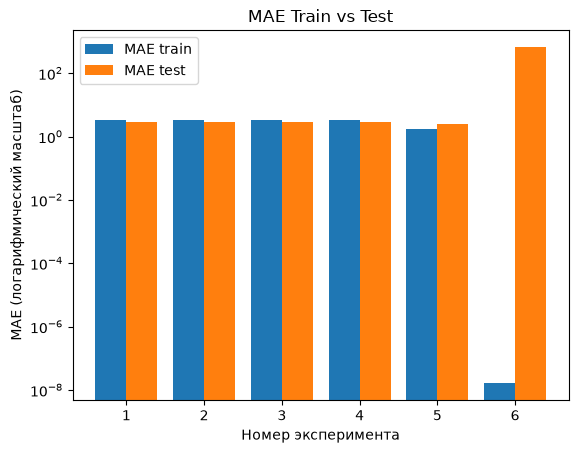

In [7]:
# Сравнение MAE на обучающей и тестовой выборках для разных параметров
labels = [1,2,3,4,5,6]
mae_train = result['MAE_train']
mae_test = result['MAE_test']
x = np.arange(len(labels))
plt.bar(x - 0.2, mae_train, width=0.4, label='MAE train')
plt.bar(x + 0.2, mae_test, width=0.4, label='MAE test')
plt.yscale('log')
plt.xticks(x, labels)
plt.title('MAE Train vs Test')
plt.xlabel('Номер эксперимента')
plt.ylabel('MAE (логарифмический масштаб)')
plt.legend()
plt.show()